In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *

df = pd.read_csv('Dataset_gym.csv')

print(df.head())
print(df.info())
print(df.isnull().sum())

   workouts_per_week  avg_workout_minutes  daily_calories_burned  sleep_hours  \
0                  0                   23                    235          5.3   
1                  6                   64                    493          7.3   
2                  5                   88                    530          7.8   
3                  3                   80                    407          7.4   
4                  3                   35                    303          7.7   

   goal_achieved  
0              0  
1              0  
2              1  
3              1  
4              0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   workouts_per_week      500 non-null    int64  
 1   avg_workout_minutes    500 non-null    int64  
 2   daily_calories_burned  500 non-null    int64  
 3   sleep_hours            500 non

goal_achieved
0    285
1    215
Name: count, dtype: int64


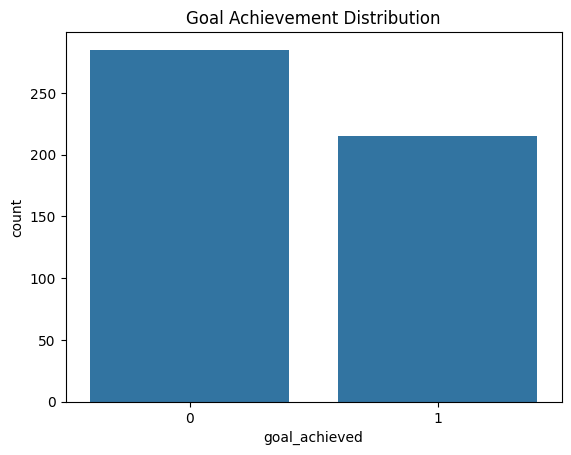

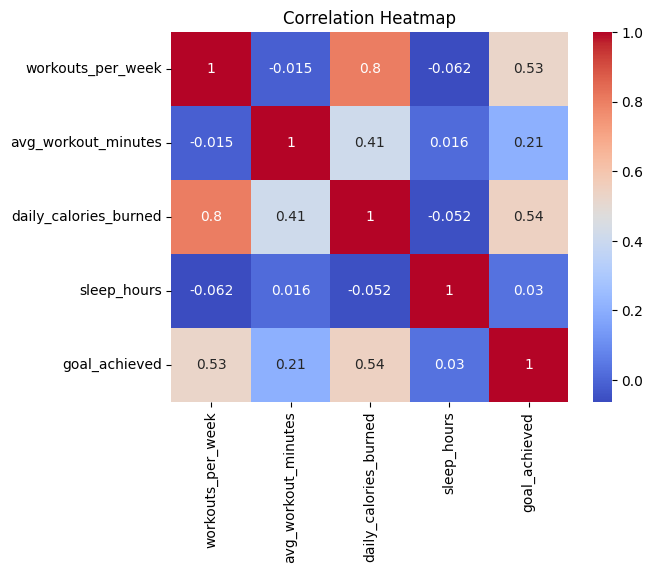

In [20]:
print(df['goal_achieved'].value_counts())

sns.countplot(x='goal_achieved', data=df)
plt.title('Goal Achievement Distribution')
plt.show()

sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


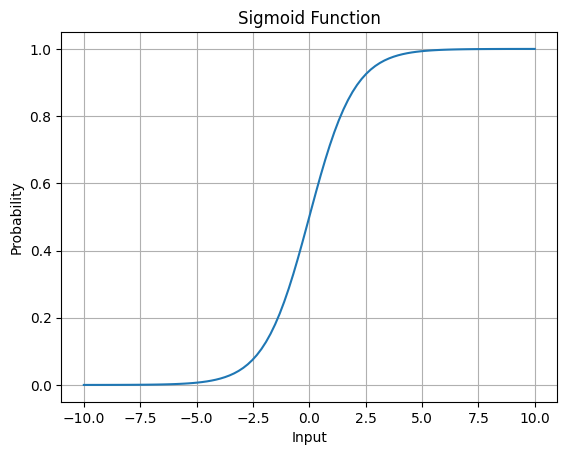

In [21]:
x = np.linspace(-10, 10, 100)
y = 1 / (1 + np.exp(-x))

plt.plot(x, y)
plt.title('Sigmoid Function')
plt.xlabel('Input')
plt.ylabel('Probability')
plt.grid()
plt.show()

In [22]:
X = df.drop('goal_achieved', axis=1)
y = df['goal_achieved']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)
print("Accuracy:", accuracy_score(y_test, y_pred))

Intercept: [-0.43336987]
Coefficients: [[0.95232143 0.40635631 0.57424622 0.22337803]]
Accuracy: 0.8


In [23]:
for t in [0.3, 0.5, 0.7]:
    pred = (y_prob >= t).astype(int)

    print("\nThreshold:", t)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred))
    print("Recall:", recall_score(y_test, pred))
    print("F1 Score:", f1_score(y_test, pred))

baseline = np.full(len(y_test), y_train.mode()[0])
print("\nMajority Class Baseline Accuracy:",
      accuracy_score(y_test, baseline))


Threshold: 0.3
Accuracy: 0.69
Precision: 0.5882352941176471
Recall: 0.9302325581395349
F1 Score: 0.7207207207207207

Threshold: 0.5
Accuracy: 0.8
Precision: 0.7674418604651163
Recall: 0.7674418604651163
F1 Score: 0.7674418604651163

Threshold: 0.7
Accuracy: 0.75
Precision: 0.9090909090909091
Recall: 0.46511627906976744
F1 Score: 0.6153846153846154

Majority Class Baseline Accuracy: 0.57


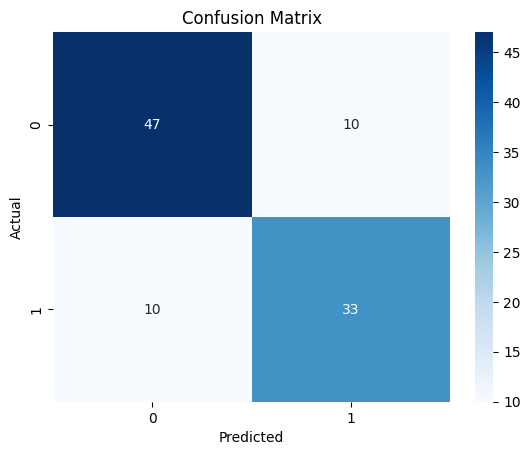

TN: 47
FP: 10
FN: 10
TP: 33

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.82      0.82        57
           1       0.77      0.77      0.77        43

    accuracy                           0.80       100
   macro avg       0.80      0.80      0.80       100
weighted avg       0.80      0.80      0.80       100

Specificity: 0.8245614035087719
ROC-AUC: 0.8347613219094246


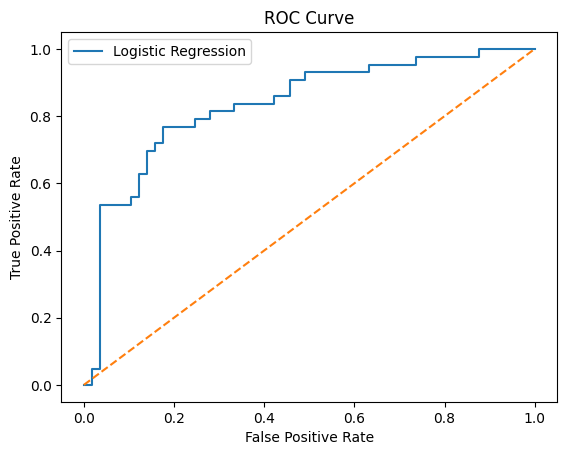

In [24]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

tn, fp, fn, tp = cm.ravel()

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Specificity:", tn / (tn + fp))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label='Logistic Regression')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

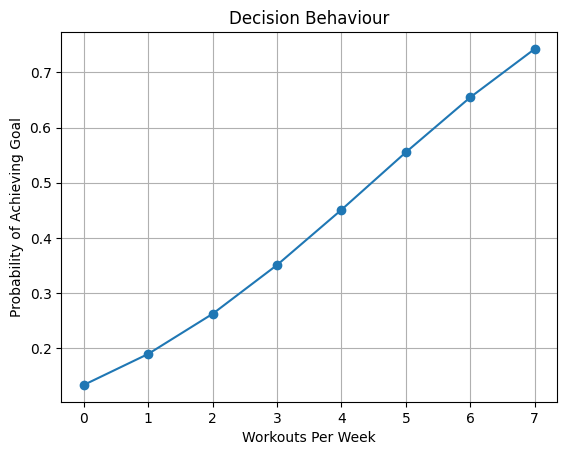

In [25]:
values = pd.DataFrame({
    'workouts_per_week': np.arange(0, 8),
    'avg_workout_minutes': [df['avg_workout_minutes'].mean()] * 8,
    'daily_calories_burned': [df['daily_calories_burned'].mean()] * 8,
    'sleep_hours': [df['sleep_hours'].mean()] * 8
})

values_scaled = scaler.transform(values)
probabilities = model.predict_proba(values_scaled)[:, 1]

plt.plot(values['workouts_per_week'], probabilities, marker='o')
plt.xlabel('Workouts Per Week')
plt.ylabel('Probability of Achieving Goal')
plt.title('Decision Behaviour')
plt.grid()
plt.show()

In [26]:
new_member = pd.DataFrame({
    'workouts_per_week': [5],
    'avg_workout_minutes': [60],
    'daily_calories_burned': [400],
    'sleep_hours': [8]
})

new_scaled = scaler.transform(new_member)

probability = model.predict_proba(new_scaled)[0][1]
prediction = model.predict(new_scaled)[0]

print("Probability of achieving goal:", round(probability * 100, 2), "%")

if prediction == 1:
    print("Predicted Result: Goal Achieved")
else:
    print("Predicted Result: Goal Not Achieved")

Probability of achieving goal: 67.29 %
Predicted Result: Goal Achieved
